In [11]:
import torch
import torchvision
from torchvision.datasets import VOCDetection
import torchvision.transforms as transforms

# Define transformations
transform = transforms.Compose([
transforms.Resize((256, 256)),
transforms.ToTensor(),
])

voc_dataset = VOCDetection(root='./voc_data',year='2012',image_set='train', download=True, transform=transform)
print(f"Number of images in the dataset : {len(voc_dataset)}")

100%|██████████| 2.00G/2.00G [01:11<00:00, 28.0MB/s] 


Number of images in the dataset : 5717


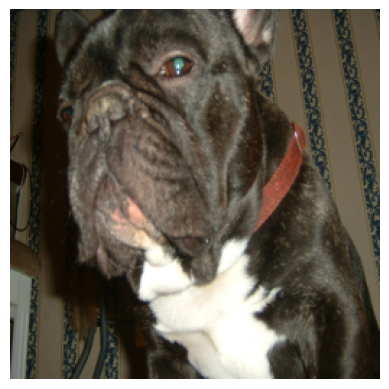

Classes in the image: ['dog']


In [13]:
import matplotlib.pyplot as plt
# Load an image and its annotation
img, annotation = voc_dataset[10] # Adjust index to explore other images
# Display the image
plt.imshow(img.permute(1, 2, 0))
plt.axis('off') # Hide axes
plt.show()
# Display classes of objects in the image
object_classes = [obj['name'] for obj in annotation['annotation']
['object']]
print("Classes in the image:", object_classes)

target_transform -> like transform only but applied to target/annotation, useful for converting annotation formats

In [14]:
import torchvision.models.detection as detection
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights

model = detection.fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
model.eval()# Set the model to inference mode

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 219MB/s] 


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

combines classification and bbox into single obj unlike r-cnn

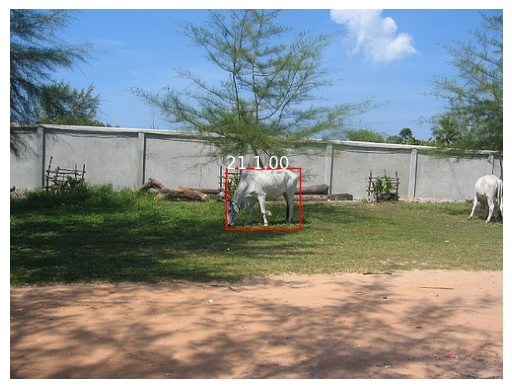

In [17]:
import torchvision.models.detection as detection
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from torchvision.transforms import functional as F
from PIL import Image
voc_dataset = VOCDetection(root='./voc_data', year='2012',
image_set='val', download=False)
image, annotation = voc_dataset[3]
# Load an image
image = image.convert("RGB")
image_tensor = F.to_tensor(image).unsqueeze(0)
with torch.no_grad():
    prediction = model(image_tensor)
    # Visualizing the results
    boxes = prediction[0]['boxes']
    labels = prediction[0]['labels']
    scores = prediction[0]['scores']
    # For simplicity, let's show the first detected object
    box = boxes[0].numpy()
    label = labels[0].item()
    score = scores[0].item()
    # Draw the bounding box and label on the image
    plt.imshow(image)
    plt.gca().add_patch(plt.Rectangle((box[0], box[1]), box[2] - box[0],
    box[3] - box[1], fill=False, color='red'))
    plt.text(box[0], box[1], f'{label} {score:.2f}', color='white',
    fontsize=12)
    plt.axis('off')
    plt.show()

In [18]:
from torch.utils.data import DataLoader

In [19]:
def get_transform(train):
    transforms_list = []
    transforms_list.append(transforms.ToTensor)
    if train:
        transform_list.append(transforms.RandomHorizontalFlip(0.5))
    return transforms.Compose(transforms_list)

class_to_label = {
'aeroplane': 1, 'bicycle': 2, 'bird': 3, 'boat': 4,
'bottle': 5, 'bus': 6, 'car': 7, 'cat': 8,
'chair': 9, 'cow': 10, 'diningtable': 11, 'dog': 12,
'horse': 13, 'motorbike': 14, 'person': 15, 'pottedplant': 16,
'sheep': 17, 'sofa': 18, 'train': 19, 'tvmonitor': 20
}

target = {
    'annotation': {
        'object': [
            {
                'name': 'dog',
                'bndbox': {
                    'xmin': '48',
                    'ymin': '240',
                    'xmax': '195',
                    'ymax': '371'
                }
            }
        ]
    }
}

this is how it looks like, we need to clean it for model to understand

In [26]:
def preprocess_target(target):
    objects = target['annotation']['object']

    # Handle the case where there's only a single object
    if not isinstance(objects, list):
        objects = [objects]

    boxes = []
    labels = []

    for obj in objects:
        bndbox = obj['bndbox']

        # Convert coordinates to float and arrange them as [xmin, ymin, xmax, ymax]
        box = [
            float(bndbox['xmin']),
            float(bndbox['ymin']),
            float(bndbox['xmax']),
            float(bndbox['ymax'])
        ]
        boxes.append(box)

        # Convert class name to numeric label
        label = class_to_label[obj['name']]
        labels.append(label)

    # Convert lists to PyTorch tensors
    boxes_tensor = torch.tensor(boxes, dtype=torch.float32)
    labels_tensor = torch.tensor(labels, dtype=torch.int64)

    # Return the processed target
    return {
        'boxes': boxes_tensor,
        'labels': labels_tensor
    }

In [28]:
transformed_dataset = [(img, preprocess_target(target)) for img, target in voc_dataset]
data_loader = DataLoader(transformed_dataset, batch_size=16,shuffle=True, num_workers=1, collate_fn=lambda x: tuple(zip(*x)))

In [29]:
import torchvision
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor,
    FasterRCNN_ResNet50_FPN_Weights
)

def get_model(num_classes):
    # Load a pretrained Faster R-CNN model
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    )

    # Get the number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features

    # Replace the pretrained classification head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features,
        num_classes
    )

    return model

# Pascal VOC: 20 object classes + 1 background class
model = get_model(num_classes=21)

In [ ]:
# Parameters
num_epochs = 2
lr = 0.005           # Learning rate
momentum = 0.9       # Uses 90% of the previous update to smooth optimization
weight_decay = 0.0005  # L2 regularization to prevent overfitting

# Optimizer
params = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.SGD(
    params,
    lr=lr,
    momentum=momentum,
    weight_decay=weight_decay
)

# Training loop
for epoch in range(num_epochs):
    model.train()

    for images, targets in data_loader:

        # Forward pass
        images = [transforms.ToTensor()(img) for img in images]
        loss_dict = model(images, targets)

        # Total loss = sum of all individual losses
        losses = sum(loss for loss in loss_dict.values())

        # Backpropagation
        optimizer.zero_grad()   # Clear gradients from previous iteration
        losses.backward()       # Compute gradients
        optimizer.step()        # Update model weights

    print(f"Epoch {epoch + 1}, Loss: {losses.item()}")

In [ ]:
import torch
import torchvision
from torchvision.datasets import VOCDetection
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from torchvision.transforms import functional as F
from torch.utils.data import DataLoader

# Ensure COCO tools are installed:
# pip install pycocotools

from pycocotools.cocoeval import COCOeval
from pycocotools.coco import COCO

import json


# -----------------------------
# Dataset Preparation
# -----------------------------
def get_transform(train):
    transforms = []
    transforms.append(torchvision.transforms.ToTensor())
    return torchvision.transforms.Compose(transforms)


def collate_fn(batch):
    return tuple(zip(*batch))


def create_dataset_val():
    dataset = VOCDetection(
        root="./voc_data",
        year="2012",
        image_set="val",
        download=False,
        transform=get_transform(train=False)
    )
    return dataset


data_loader_val = DataLoader(
    create_dataset_val(),
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=4
)


# -----------------------------
# Model Loading
# -----------------------------
model = fasterrcnn_resnet50_fpn(
    weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT
)

model.eval()


# -----------------------------
# Evaluation
# -----------------------------
def evaluate(model, data_loader):

    model.eval()

    coco = COCO()          # Placeholder
    coco_dt = []

    image_id = 0

    for images, targets in data_loader:

        # SAME FIX AS TRAINING
        images = [
            torchvision.transforms.ToTensor()(img)
            if not isinstance(img, torch.Tensor)
            else img
            for img in images
        ]

        with torch.no_grad():
            outputs = model(images)

        for output in outputs:

            pred_boxes = output["boxes"].cpu().numpy()
            pred_scores = output["scores"].cpu().numpy()
            pred_labels = output["labels"].cpu().numpy()

            for idx in range(len(pred_boxes)):

                detection = {
                    "image_id": image_id,
                    "category_id": int(pred_labels[idx]),
                    "bbox": [float(x) for x in pred_boxes[idx]],
                    "score": float(pred_scores[idx])
                }

                coco_dt.append(detection)

            image_id += 1

    with open("coco_dt.json", "w") as f:
        json.dump(coco_dt, f)

    cocoDt = coco.loadRes("coco_dt.json")

    cocoEval = COCOeval(coco, cocoDt, "bbox")
    cocoEval.evaluate()
    cocoEval.accumulate()
    cocoEval.summarize()


evaluate(model, data_loader_val)

In [34]:
import torchvision.models.detection as detection
import torchvision.models.detection.ssd as ssd
from torchvision.models.detection import SSD300_VGG16_Weights
# Load the pretrained SSD model
model = detection.ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)
model.eval() # Switch the model to inference mode

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 173MB/s]  


SSD(
  (backbone): SSDFeatureExtractorVGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=

imp features of ssd:
processes images through different series of convolutional layers, to detect objects of all sizes
- joint loacalisation and classification


In [36]:
import torchvision.models.detection as detection
import torchvision.models.detection.ssd as ssd
from torchvision.datasets import VOCDetection
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision.models.detection import SSD300_VGG16_Weights

In [37]:
model = detection.ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)
model.eval()

SSD(
  (backbone): SSDFeatureExtractorVGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=

In [39]:
def transform_image(image):
    transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.ToTensor()
    ])
    return transform(image).unsqueeze(0)

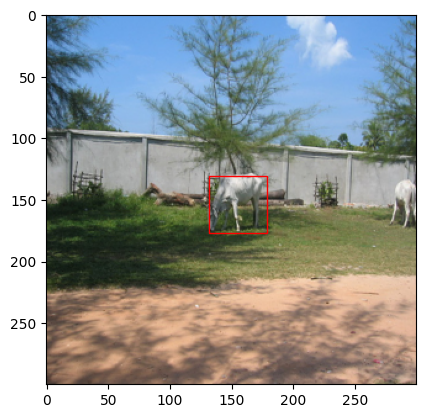

In [40]:
# Load an example image from the PASCAL VOC dataset
dataset = VOCDetection(
    root="./voc_data",
    year="2012",
    image_set="val",
    download=False
)

# Sample image
image, _ = dataset[3]

# Apply preprocessing
image = transform_image(image)

# Perform inference
with torch.no_grad():
    prediction = model(image)

# Extract predictions
det_boxes = prediction[0]["boxes"]
det_labels = prediction[0]["labels"]
det_scores = prediction[0]["scores"]

# Display the image and detected bounding boxes
fig, ax = plt.subplots(1)

ax.imshow(image.squeeze().permute(1, 2, 0))

for box in det_boxes:
    rect = plt.Rectangle(
        (box[0], box[1]),
        box[2] - box[0],
        box[3] - box[1],
        fill=False,
        color="red"
    )
    ax.add_patch(rect)

    # Show only the first detected box
    break

plt.show()